# Cohort spatial averaging QC

This notebook combines fixed-K spatial averaging and target-group-size results. Subject-level summaries are computed before cohort summaries.

In [ ]:

from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import display

RESULT_ROOT = Path(
    "/mnt/newStor/paros/paros_WORK/xintong/results/native_surface_analysis"
)


def read_metric_files(paths):
    frames = [pd.read_csv(path) for path in paths if path.exists()]
    if not frames:
        return pd.DataFrame()
    return pd.concat(frames, ignore_index=True)


fixed_paths = [
    RESULT_ROOT / "spatial_averaging_pilot/tables/metrics_summary.csv",
]
fixed_paths.extend(
    sorted(
        (
            RESULT_ROOT / "spatial_averaging_five_subjects/shards"
        ).glob("D*/tables/metrics_summary.csv")
    )
)
fixed_paths.extend(
    sorted(
        (
            RESULT_ROOT / "spatial_averaging_k64_k128/shards"
        ).glob("D*/tables/metrics_summary.csv")
    )
)
fixed_paths.extend(
    sorted(
        (
            RESULT_ROOT / "spatial_averaging_fixed_k_40/shards"
        ).glob("D*/tables/metrics_summary.csv")
    )
)

fixed = read_metric_files(fixed_paths)
fixed = fixed.drop_duplicates(
    subset=["subject", "hemisphere", "region", "method", "k", "repeat"]
)
fixed = fixed[fixed.status.eq("valid")].copy()
fixed = fixed[fixed.method.isin(["region", "spatial", "random"])]
fixed = fixed[fixed.k.isin([1, 2, 4, 8, 16, 32, 64, 128])]

target_paths = sorted(
    (RESULT_ROOT / "spatial_averaging_target_sizes").glob(
        "D*/tables/target_group_size_metrics.csv"
    )
)
target_paths += sorted(
    (RESULT_ROOT / "spatial_averaging_target_sizes_existing").glob(
        "D*/tables/target_group_size_metrics.csv"
    )
)
target = read_metric_files(target_paths)
target = target.drop_duplicates(
    subset=["subject", "hemisphere", "region", "target_group_size", "k"]
)
target = target[target.status.eq("valid")].copy()

connectivity_paths = [
    RESULT_ROOT / "spatial_averaging_pilot/tables/spatial_group_connectivity.csv",
]
connectivity_paths.extend(
    sorted(
        (
            RESULT_ROOT / "spatial_averaging_five_subjects/shards"
        ).glob("D*/tables/spatial_group_connectivity.csv")
    )
)
connectivity_paths.extend(
    sorted(
        (
            RESULT_ROOT / "spatial_averaging_k64_k128/shards"
        ).glob("D*/tables/spatial_group_connectivity.csv")
    )
)
connectivity_paths.extend(
    sorted(
        (
            RESULT_ROOT / "spatial_averaging_fixed_k_40/shards"
        ).glob("D*/tables/spatial_group_connectivity.csv")
    )
)
connectivity = read_metric_files(connectivity_paths)
connectivity = connectivity[
    connectivity.method.eq("spatial")
].copy()
connectivity = connectivity[
    connectivity.k.isin([1, 2, 4, 8, 16, 32, 64, 128])
].copy()

print(f"Fixed-K subjects: {fixed.subject.nunique()}")
print(f"Target-size subjects: {target.subject.nunique()}")
print(f"Fixed-K rows: {len(fixed):,}")
print(f"Target-size rows: {len(target):,}")
display(target.groupby("target_group_size")["subject"].nunique())


Fixed-K subjects: 40
Target-size subjects: 39
Fixed-K rows: 34,135
Target-size rows: 1,093


target_group_size
50     39
100    39
200    39
400    39
Name: subject, dtype: int64

## Subject-level fixed-K metrics

In [ ]:

keys = ["subject", "hemisphere", "region", "method", "k"]
subject_metrics = fixed.groupby(keys, as_index=False).agg(
    mae=("mae", "median"),
    rmse=("rmse", "median"),
)
baseline = subject_metrics[
    subject_metrics.method.eq("region") & subject_metrics.k.eq(1)
].rename(columns={"mae": "baseline_mae", "rmse": "baseline_rmse"})[
    ["subject", "hemisphere", "region", "baseline_mae", "baseline_rmse"]
]
subject_metrics = subject_metrics.merge(
    baseline,
    on=["subject", "hemisphere", "region"],
    how="left",
)
subject_metrics["mae_improvement_pct"] = 100 * (
    subject_metrics.baseline_mae - subject_metrics.mae
) / subject_metrics.baseline_mae
subject_metrics["rmse_improvement_pct"] = 100 * (
    subject_metrics.baseline_rmse - subject_metrics.rmse
) / subject_metrics.baseline_rmse
display(subject_metrics.head())


,subject,hemisphere,region,method,k,mae,rmse,baseline_mae,baseline_rmse,mae_improvement_pct,rmse_improvement_pct
0,D0007,lh,precentral,random,1,0.000199,0.000248,0.000199,0.000248,0.000000,0.000000
1,D0007,lh,precentral,random,2,0.000199,0.000248,0.000199,0.000248,-0.011350,-0.014595
2,D0007,lh,precentral,random,4,0.000199,0.000248,0.000199,0.000248,-0.025099,-0.033643
3,D0007,lh,precentral,random,8,0.000199,0.000248,0.000199,0.000248,-0.057611,-0.060702
4,D0007,lh,precentral,random,16,0.000199,0.000248,0.000199,0.000248,-0.104654,-0.128818


## Subject-level MAE curves through K=32

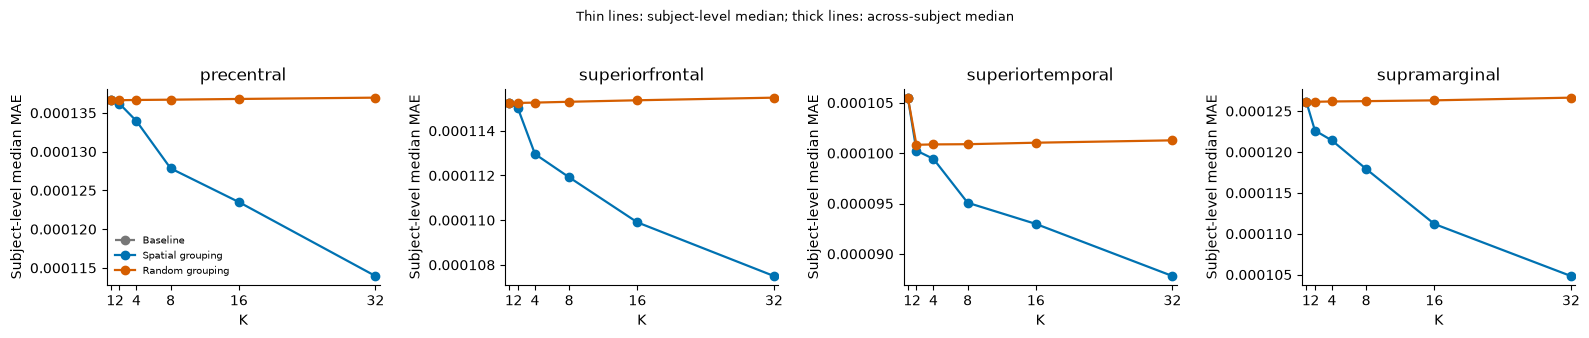

In [ ]:

plot_data = subject_metrics[subject_metrics.k.le(32)].copy()
plot_data = plot_data.groupby(
    ["subject", "region", "method", "k"], as_index=False
).agg(mae=("mae", "median"))
regions = sorted(plot_data.region.unique())
method_styles = {
    "region": ("#777777", "--", "Baseline"),
    "spatial": ("#0072B2", "-", "Spatial grouping"),
    "random": ("#D55E00", "-", "Random grouping"),
}

fig, axes = plt.subplots(
    1,
    len(regions),
    figsize=(4 * len(regions), 3.4),
    squeeze=False,
)
for ax, region in zip(axes.ravel(), regions):
    region_data = plot_data[plot_data.region.eq(region)]
    for method, (color, linestyle, label) in method_styles.items():
        method_data = region_data[region_data.method.eq(method)]
        median = method_data.groupby("k", as_index=False).mae.median()
        ax.plot(
            median.k,
            median.mae,
            color=color,
            linestyle=linestyle,
            marker="o",
            linewidth=1.6,
            label=label,
        )
    ax.set_title(region)
    ax.set_xlabel("K")
    ax.set_ylabel("Subject-level median MAE")
    ax.set_xticks([1, 2, 4, 8, 16, 32])
    ax.set_xlim(0.5, 32.5)
    ax.spines[["top", "right"]].set_visible(False)
axes.ravel()[0].legend(frameon=False, fontsize=7)
fig.suptitle(
    "Thin lines: subject-level median; thick lines: across-subject median",
    fontsize=9,
)
fig.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()


## Subject-level improvement curves

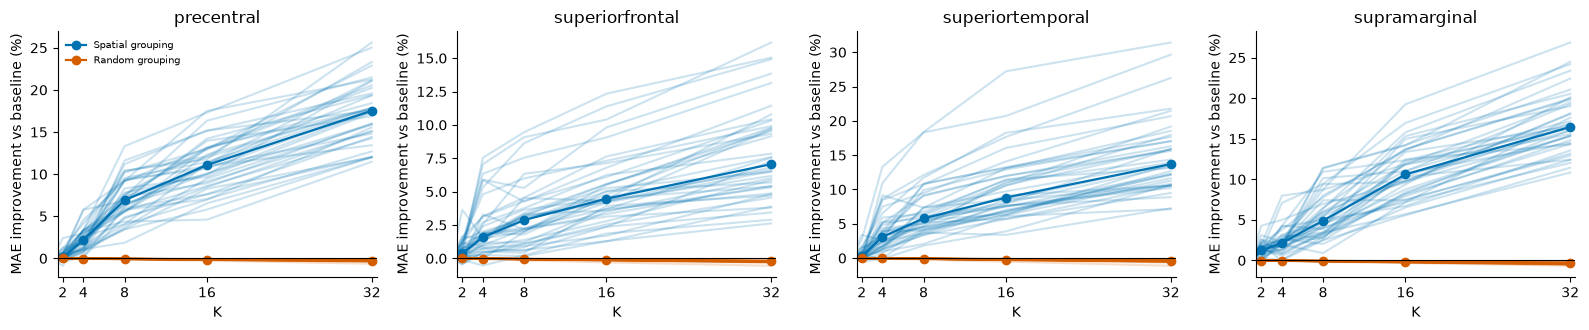

In [ ]:

plot_data = subject_metrics[
    subject_metrics.method.isin(["spatial", "random"])
].copy()
plot_data = plot_data.groupby(
    ["subject", "region", "method", "k"], as_index=False
).agg(mae_improvement_pct=("mae_improvement_pct", "median"))
regions = sorted(plot_data.region.unique())
method_styles = {
    "spatial": ("#0072B2", "Spatial grouping"),
    "random": ("#D55E00", "Random grouping"),
}

fig, axes = plt.subplots(
    1,
    len(regions),
    figsize=(4 * len(regions), 3.4),
    squeeze=False,
)
for ax, region in zip(axes.ravel(), regions):
    region_data = plot_data[plot_data.region.eq(region)]
    for method, (color, label) in method_styles.items():
        method_data = region_data[
            region_data.method.eq(method) & region_data.k.le(32)
        ]
        for subject, group in method_data.groupby("subject"):
            group = group.sort_values("k")
            ax.plot(group.k, group.mae_improvement_pct, color=color, alpha=0.2)
        median = method_data.groupby("k", as_index=False).mae_improvement_pct.median()
        ax.plot(
            median.k,
            median.mae_improvement_pct,
            color=color,
            marker="o",
            linewidth=1.6,
            label=label,
        )
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_title(region)
    ax.set_xlabel("K")
    ax.set_ylabel("MAE improvement vs baseline (%)")
    ax.set_xticks([2, 4, 8, 16, 32])
    ax.set_xlim(1.5, 32.5)
    ax.spines[["top", "right"]].set_visible(False)
axes.ravel()[0].legend(frameon=False, fontsize=7)
fig.tight_layout()
plt.show()



## Spatial grouping improvement

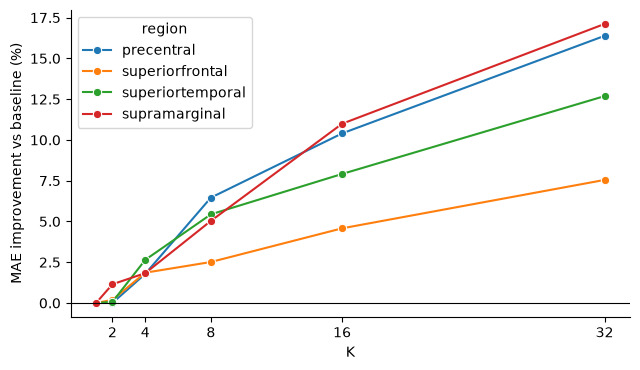

In [ ]:

summary = subject_metrics.groupby(
    ["region", "method", "k"], as_index=False
).agg(
    n_subjects=("subject", "nunique"),
    mae_median=("mae", "median"),
    mae_q25=("mae", lambda values: values.quantile(0.25)),
    mae_q75=("mae", lambda values: values.quantile(0.75)),
    improvement_median=("mae_improvement_pct", "median"),
    improvement_q25=("mae_improvement_pct", lambda values: values.quantile(0.25)),
    improvement_q75=("mae_improvement_pct", lambda values: values.quantile(0.75)),
)
spatial = summary[
    summary.method.eq("spatial") & summary.k.le(32)
].copy()
fig, ax = plt.subplots(figsize=(6.5, 3.8))
sns.lineplot(
    data=spatial,
    x="k",
    y="improvement_median",
    hue="region",
    marker="o",
    ax=ax,
)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xlabel("K")
ax.set_ylabel("MAE improvement vs baseline (%)")
ax.set_xticks([2, 4, 8, 16, 32])
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()



## Fixed-column-count grouping

,region,target_group_size,n_subjects,n_subjects_improvement,mae_median,mae_q25,mae_q75,improvement_median,improvement_q25,improvement_q75
0,precentral,50,32,44,0.0001,0.0001,0.0001,35.4358,31.2179,39.1235
1,precentral,100,39,78,0.0001,0.0001,0.0001,28.3162,23.7567,31.3108
2,precentral,200,39,78,0.0001,0.0001,0.0001,19.2346,15.2759,22.5722
3,precentral,400,39,78,0.0001,0.0001,0.0001,12.2743,9.9869,15.3475
4,superiorfrontal,50,28,40,0.0001,0.0001,0.0001,26.3261,23.8785,30.5187
5,superiorfrontal,100,39,78,0.0001,0.0001,0.0001,17.0614,14.6819,20.5963
6,superiorfrontal,200,39,78,0.0001,0.0001,0.0001,10.8602,8.0177,13.9471
7,superiorfrontal,400,39,78,0.0001,0.0001,0.0001,6.3373,4.2546,8.0036
8,superiortemporal,50,22,28,0.0001,0.0001,0.0001,22.6027,18.9923,28.6124
9,superiortemporal,100,39,71,0.0001,0.0001,0.0001,16.8044,13.9647,23.0646


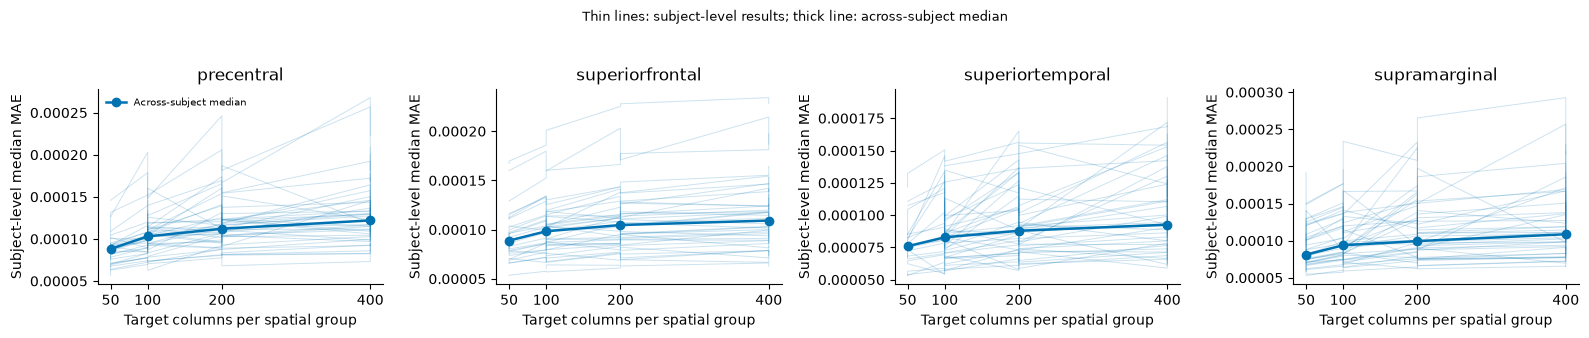

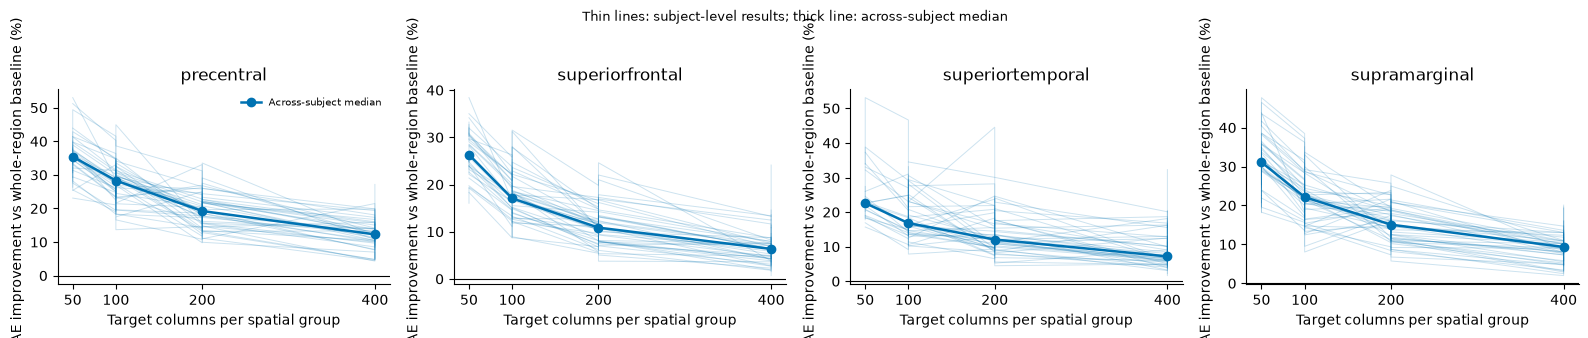

In [ ]:

target_subject = target.groupby(
    ["subject", "hemisphere", "region", "target_group_size"],
    as_index=False,
).agg(mae=("mae", "median"), rmse=("rmse", "median"))
target_baseline = subject_metrics[
    subject_metrics.method.eq("region") & subject_metrics.k.eq(1)
][
    ["subject", "hemisphere", "region", "baseline_mae"]
].drop_duplicates()
target_subject = target_subject.merge(
    target_baseline,
    on=["subject", "hemisphere", "region"],
    how="left",
)
target_subject["mae_improvement_pct"] = 100 * (
    target_subject.baseline_mae - target_subject.mae
) / target_subject.baseline_mae

target_summary = target_subject.groupby(
    ["region", "target_group_size"], as_index=False
).agg(
    n_subjects=("subject", "nunique"),
    n_subjects_improvement=("mae_improvement_pct", lambda values: values.notna().sum()),
    mae_median=("mae", "median"),
    mae_q25=("mae", lambda values: values.quantile(0.25)),
    mae_q75=("mae", lambda values: values.quantile(0.75)),
    improvement_median=("mae_improvement_pct", "median"),
    improvement_q25=("mae_improvement_pct", lambda values: values.quantile(0.25)),
    improvement_q75=("mae_improvement_pct", lambda values: values.quantile(0.75)),
)
display(target_summary.round(4))

regions = sorted(target_summary.region.unique())
fig, axes = plt.subplots(
    1,
    len(regions),
    figsize=(4 * len(regions), 3.4),
    squeeze=False,
)
for ax, region in zip(axes.ravel(), regions):
    subject_part = target_subject[target_subject.region.eq(region)]
    for subject, group in subject_part.groupby("subject"):
        group = group.sort_values("target_group_size")
        ax.plot(
            group.target_group_size,
            group.mae,
            color="#0072B2",
            alpha=0.2,
            linewidth=0.7,
        )
    part = target_summary[target_summary.region.eq(region)]
    ax.plot(
        part.target_group_size,
        part.mae_median,
        color="#0072B2",
        marker="o",
        linewidth=1.8,
        label="Across-subject median",
    )
    ax.set_title(region)
    ax.set_xlabel("Target columns per spatial group")
    ax.set_ylabel("Subject-level median MAE")
    ax.set_xticks(sorted(target_summary.target_group_size.unique()))
    ax.spines[["top", "right"]].set_visible(False)
axes.ravel()[0].legend(frameon=False, fontsize=7)
fig.suptitle(
    "Thin lines: subject-level results; thick line: across-subject median",
    fontsize=9,
)
fig.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

regions = sorted(target_summary.region.unique())
fig, axes = plt.subplots(
    1,
    len(regions),
    figsize=(4 * len(regions), 3.4),
    squeeze=False,
)
for ax, region in zip(axes.ravel(), regions):
    subject_part = target_subject[target_subject.region.eq(region)]
    for subject, group in subject_part.groupby("subject"):
        group = group.sort_values("target_group_size")
        ax.plot(
            group.target_group_size,
            group.mae_improvement_pct,
            color="#0072B2",
            alpha=0.2,
            linewidth=0.7,
        )
    part = target_summary[target_summary.region.eq(region)]
    ax.plot(
        part.target_group_size,
        part.improvement_median,
        color="#0072B2",
        marker="o",
        linewidth=1.8,
        label="Across-subject median",
    )
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_title(region)
    ax.set_xlabel("Target columns per spatial group")
    ax.set_ylabel("MAE improvement vs whole-region baseline (%)")
    ax.set_xticks(sorted(target_summary.target_group_size.unique()))
    ax.spines[["top", "right"]].set_visible(False)
axes.ravel()[0].legend(frameon=False, fontsize=7)
fig.suptitle(
    "Thin lines: subject-level results; thick line: across-subject median",
    fontsize=9,
)
fig.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()


## Number of columns per K-based spatial group

,region,k,n_subjects,n_groups,mean_columns_per_group,median_columns_per_group,q25_columns_per_group,q75_columns_per_group,min_columns_per_group,max_columns_per_group
0,precentral,1,40,80,7568.78,7338.5,6822.75,8216.50,4668,10622
1,precentral,2,40,160,3784.39,3806.0,2887.50,4431.50,1923,6060
2,precentral,4,40,320,1892.19,1795.5,1149.25,2458.25,382,4551
3,precentral,8,40,640,946.10,892.5,643.50,1195.00,204,2334
4,precentral,16,40,1280,473.05,406.0,299.75,600.25,98,1540
5,precentral,32,40,2560,236.52,213.0,145.00,311.25,44,700
6,precentral,64,9,1152,124.89,116.0,80.00,158.00,18,399
7,precentral,128,9,2304,62.45,58.0,42.00,77.00,8,214
8,superiorfrontal,1,40,80,10122.55,10097.0,8903.50,11091.50,5247,14875
9,superiorfrontal,2,40,160,5061.27,4961.0,3948.75,6153.50,2228,9141


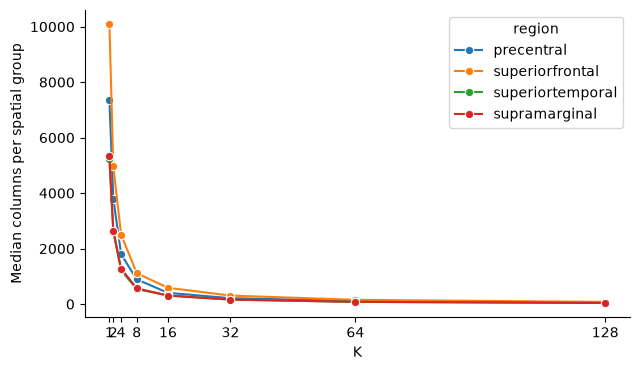

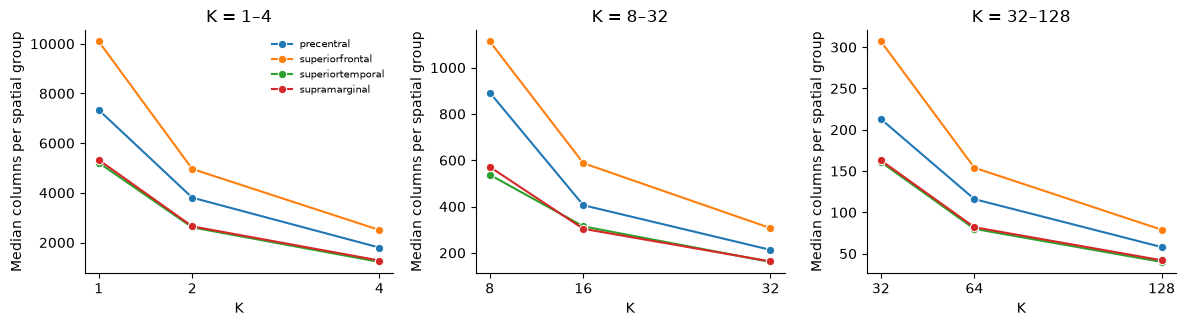

In [ ]:

group_size_summary = connectivity.groupby(
    ["region", "k"], as_index=False
).agg(
    n_subjects=("subject", "nunique"),
    n_groups=("n_columns", "size"),
    mean_columns_per_group=("n_columns", "mean"),
    median_columns_per_group=("n_columns", "median"),
    q25_columns_per_group=("n_columns", lambda values: values.quantile(0.25)),
    q75_columns_per_group=("n_columns", lambda values: values.quantile(0.75)),
    min_columns_per_group=("n_columns", "min"),
    max_columns_per_group=("n_columns", "max"),
)
display(group_size_summary.round(2))

group_size_long = group_size_summary.melt(
    id_vars=["region", "k"],
    value_vars=[
        "mean_columns_per_group",
        "median_columns_per_group",
        "q25_columns_per_group",
        "q75_columns_per_group",
    ],
    var_name="statistic",
    value_name="columns",
)
fig, ax = plt.subplots(figsize=(6.5, 3.8))
sns.lineplot(
    data=group_size_long[group_size_long.statistic.eq("median_columns_per_group")],
    x="k",
    y="columns",
    hue="region",
    marker="o",
    ax=ax,
)
ax.set_xlabel("K")
ax.set_ylabel("Median columns per spatial group")
ax.set_xticks(sorted(connectivity.k.unique()))
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(12.0, 3.4), squeeze=False)
for ax, k_values, label in zip(
    axes.ravel(),
    ([1, 2, 4], [8, 16, 32], [32, 64, 128]),
    ("K = 1–4", "K = 8–32", "K = 32–128"),
):
    plot_data = group_size_long[
        group_size_long.statistic.eq("median_columns_per_group")
        & group_size_long.k.isin(k_values)
    ]
    sns.lineplot(
        data=plot_data,
        x="k",
        y="columns",
        hue="region",
        marker="o",
        ax=ax,
    )
    ax.set_title(label)
    ax.set_xlabel("K")
    ax.set_ylabel("Median columns per spatial group")
    ax.set_xticks(k_values)
    ax.spines[["top", "right"]].set_visible(False)
    if ax is not axes.ravel()[0]:
        ax.get_legend().remove()
axes.ravel()[0].legend(frameon=False, fontsize=7)
fig.tight_layout(pad=1.2)
plt.show()



## Actual group size versus improvement

Scatter K values: [np.int64(1), np.int64(2), np.int64(4), np.int64(8), np.int64(16), np.int64(32), np.int64(64), np.int64(128)]


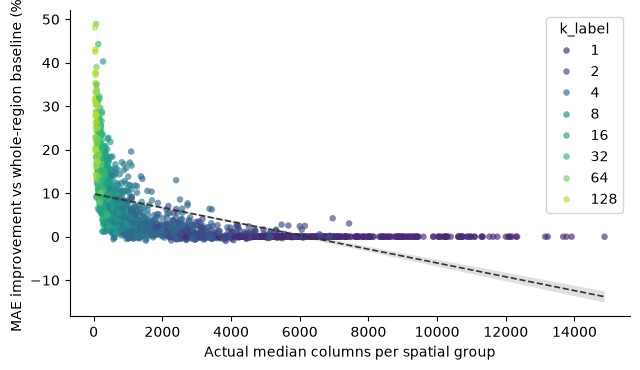

In [ ]:

group_size_by_unit = connectivity.groupby(
    ["subject", "hemisphere", "region", "k"],
    as_index=False,
).agg(
    median_columns_per_group=("n_columns", "median"),
)
spatial_improvement = subject_metrics[
    subject_metrics.method.eq("spatial")
][
    ["subject", "hemisphere", "region", "k", "mae_improvement_pct"]
].drop_duplicates()
scatter_data = group_size_by_unit.merge(
    spatial_improvement,
    on=["subject", "hemisphere", "region", "k"],
    how="inner",
)
fixed_k_values = [1, 2, 4, 8, 16, 32, 64, 128]
scatter_data = scatter_data[scatter_data.k.isin(fixed_k_values)].copy()
scatter_data["k_label"] = scatter_data.k.astype(int).astype(str)
print("Scatter K values:", sorted(scatter_data.k.unique()))

plt.close("all")
fig, ax = plt.subplots(figsize=(6.5, 3.8))
sns.scatterplot(
    data=scatter_data,
    x="median_columns_per_group",
    y="mae_improvement_pct",
    hue="k_label",
    hue_order=[str(value) for value in fixed_k_values],
    palette=dict(
        zip(
            [str(value) for value in fixed_k_values],
            sns.color_palette("viridis", n_colors=len(fixed_k_values)),
        )
    ),
    s=22,
    alpha=0.65,
    edgecolor="none",
    ax=ax,
)
if len(scatter_data) >= 2:
    sns.regplot(
        data=scatter_data,
        x="median_columns_per_group",
        y="mae_improvement_pct",
        scatter=False,
        color="#333333",
        line_kws={"linewidth": 1.2, "linestyle": "--"},
        ax=ax,
    )
ax.set_xlabel("Actual median columns per spatial group")
ax.set_ylabel("MAE improvement vs whole-region baseline (%)")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()
